<h3>Variational Autoencoder</h3>

<img src="https://res.cloudinary.com/dpyleb8ih/image/upload/v1560249262/vae-gaussian.png" width="500" height="250">

We're trying to build a generative model here, not just a fuzzy data structure that can "memorize" images. Vanilla and Convolutional autoencoders can't generate anything yet, since we don't know how to create latent vectors other than encoding them from images.

There's a simple solution here. We add a constraint on the encoding network, that forces it to generate latent vectors that roughly follow a unit gaussian distribution. It is this constraint that separates a variational autoencoder from a standard one.

Generating new images is now easy: all we need to do is sample a latent vector from the unit gaussian and pass it into the decoder.

In practice, there's a tradeoff between how accurate our network can be and how close its latent variables can match the unit gaussian distribution.

We let the network decide this itself. For our loss term, we sum up two separate losses: the generative loss, which is a mean squared error that measures how accurately the network reconstructed the images, and a latent loss, which is the KL divergence that measures how closely the latent variables match a unit gaussian.

In [1]:
import numpy as np
import pandas as pd
import os

import matplotlib.pyplot as plt
import tensorflow as tf
from keras.datasets import mnist, fashion_mnist
from keras.layers import Input,Dense,Lambda
from keras.models import Model
from keras.preprocessing import image

from tensorflow.keras.utils import plot_model

In [2]:
num_features = 784 # data features (img shape: 28*28).

hidden_dim = 512
batch_size = 128
epochs = 50
latent_dim = 2 # The bigger this is, more accurate the network is but 2 is for illustration purposes.

In [ ]:
def sampling(args):
    """Reparameterization trick. Instead of sampling from Q(z|X), 
    sample eps = N(0,I) z = z_mean + sqrt(var)*eps.

    Parameters:
    -----------
    args: list of Tensors
        Mean and log of variance of Q(z|X)

    Returns
    -------
    z: Tensor
        Sampled latent vector
    """

    z_mean, z_log_var = args
    eps = tf.random.normal(tf.shape(z_log_var), dtype=tf.float32, mean=0., stddev=1.0, name='epsilon')
    return z_mean + tf.exp(0.5 * z_log_var) * eps

In [4]:
#Encoder

inputs = Input(shape=(num_features, ), name='input')
x = Dense(hidden_dim, activation='relu')(inputs)
z_mean = Dense(latent_dim, name='z_mean')(x)
z_log_var = Dense(latent_dim, name='z_log_var')(x)

# encoder = Model(inputs,[z_mean, z_log_var], name='encoder')
# plot_model(encoder, show_shapes=True)

<h4>Sampling Layer</h4>
Use reparameterization trick to push the sampling out as input

In [5]:
z = Lambda(sampling, name='z')([z_mean, z_log_var])

#Instantiate encoder model
encoder = Model(inputs, [z_mean, z_log_var, z], name='encoder')
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input (InputLayer)  │ (None, 784)       │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 512)       │    401,920 │ input[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │      1,026 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │      1,026 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z (Lambda)          │ (None, 2)         │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 403,972 (1.54 MB)

 Trainable params: 403,972 (1.54 MB)

 Non-trainable params: 0 (0.00 B)

<h3>Decoder</h3>

In [6]:
latent_inputs = Input(shape=(latent_dim,), name='z_sampling')
x = Dense(hidden_dim, activation='relu')(latent_inputs)
outputs = Dense(num_features, activation='sigmoid')(x)

# instantiate decoder model
decoder = Model(latent_inputs, outputs, name='decoder')
decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ z_sampling (InputLayer)              │ (None, 2)                   │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 512)                 │           1,536 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 784)                 │         402,192 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 403,728 (1.54 MB)

 Trainable params: 403,728 (1.54 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# # VAE model = encoder + decoder
outputs = decoder(encoder(inputs)[2]) # Select the Z val ue from outputs of the decoder
vae = Model(inputs, outputs, name='vae')

<h4>Define VAE loss</h4>

In [8]:
import keras
from keras import layers,ops

In [9]:
class VAELossLayer(layers.Layer):
    def __init__(self, num_features, **kwargs):
        super().__init__(**kwargs)
        self.num_features = num_features

    def call(self, inputs):
        x, x_hat, z_mean, z_log_var = inputs

        # per-sample reconstruction loss
        recon = ops.mean(ops.square(x - x_hat), axis=-1) * self.num_features

        # per-sample KL loss
        kl_term = 1 + z_log_var - ops.square(z_mean) - ops.exp(z_log_var)
        kl = -0.5 * ops.sum(kl_term, axis=-1)

        self.add_loss(ops.mean(recon + kl))
        return x_hat

In [10]:
outputs = VAELossLayer(num_features)([inputs, outputs, z_mean, z_log_var])
vae = keras.Model(inputs, outputs)
vae.compile(optimizer="adam")

In [11]:
vae.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input (InputLayer)            │ (None, 784)               │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ encoder (Functional)          │ [(None, 2), (None, 2),    │         403,972 │ input[0][0]                │
│                               │ (None, 2)]                │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 512)               │         401,920 │ input[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ decoder (Functional)          │ (None, 784)               │         403,728 │ encoder[0][2]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ z_mean (Dense)                │ (None, 2)                 │           1,026 │ dense[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ z_log_var (Dense)             │ (None, 2)                 │           1,026 │ dense[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ vae_loss_layer (VAELossLayer) │ (None, 784)               │               0 │ input[0][0],               │
│                               │                           │                 │ decoder[0][0],             │
│                               │                           │                 │ z_mean[0][0],              │
│                               │                           │                 │ z_log_var[0][0]            │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 807,700 (3.08 MB)

 Trainable params: 807,700 (3.08 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
from tensorflow.keras.datasets import mnist, fashion_mnist

def load_data(choice='mnist', labels=False):
    if choice not in ['mnist', 'fashion_mnist']:
        raise ('Choices are mnist and fashion_mnist')
    
    if choice == 'mnist':
        (X_train, y_train), (X_test, y_test) = mnist.load_data()
    else:
        (X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()
    
    X_train, X_test = X_train / 255., X_test / 255.
    X_train, X_test = X_train.reshape([-1, 784]), X_test.reshape([-1, 784])
    X_train = X_train.astype(np.float32, copy=False)
    X_test = X_test.astype(np.float32, copy=False)
    
    if labels:
        return (X_train, y_train), (X_test, y_test)
    
    return X_train, X_test

In [37]:
(X_train, _),  (X_test, y) = load_data('mnist', labels=True)

In [60]:
vae.fit(X_train, epochs=epochs, batch_size=batch_size, validation_data=(X_test,None))

Epoch 1/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - loss: 52.3508 - val_loss: 44.4214
Epoch 2/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 43.5539 - val_loss: 42.6892
Epoch 3/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 42.3902 - val_loss: 41.8780
Epoch 4/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 41.6705 - val_loss: 41.1570
Epoch 5/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 41.1218 - val_loss: 40.7850
Epoch 6/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 40.7136 - val_loss: 40.4148
Epoch 7/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 40.3748 - val_loss: 40.1193
Epoch 8/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 40.0907 - val_loss: 39.9005
Epoch 9/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 39.8446 - val_loss: 39.6744
Epoch 10/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 39.6229 - val_loss: 39.4827
Epoch 11/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 39.3991 - val_loss: 39.2684
Epoch 12/50
469/469 ━━━━

In [13]:
def generate_manifold(decoder):
    import numpy as np
    import matplotlib.pyplot as plt

    n = 30
    digit_size = 28
    figure = np.zeros((digit_size * n, digit_size * n))

    grid_x = np.linspace(-4, 4, n)
    grid_y = np.linspace(-4, 4, n)[::-1]

    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):
            z_sample = np.array([[xi, yi]], dtype="float32")
            x_decoded = decoder.predict(z_sample, verbose=0)
            digit = x_decoded[0].reshape(digit_size, digit_size)
            figure[
                i * digit_size : (i + 1) * digit_size,
                j * digit_size : (j + 1) * digit_size
            ] = digit

    plt.figure(figsize=(10, 10))
    start_range = digit_size // 2

    # exactly n tick locations
    pixel_range = start_range + np.arange(n) * digit_size

    plt.xticks(pixel_range, np.round(grid_x, 1))
    plt.yticks(pixel_range, np.round(grid_y, 1))
    plt.xlabel("z[0] Latent Dimension")
    plt.ylabel("z[1] Latent Dimension")
    plt.imshow(figure, cmap="Greys_r")
    plt.show()

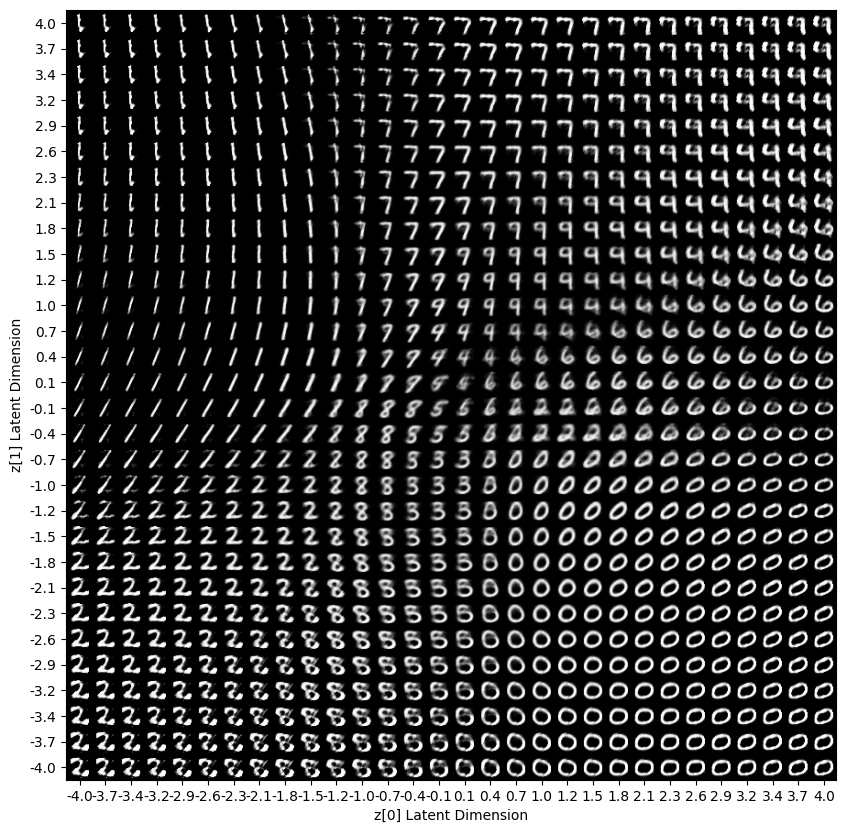

In [67]:
generate_manifold(decoder)

In [14]:
def plot_digits(X, y, encoder, batch_size=128):
    """Plots labels and MNIST digits as function of 2D latent vector

    Parameters:
    ----------
    encoder: Model
        A Keras Model instance
    X: np.ndarray
        Test data
    y: np.ndarray
        Test data labels
    batch_size: int
        Prediction batch size
    """
    # display a 2D plot of the digit classes in the latent space
    z_mean, _, _ = encoder.predict(X, batch_size=batch_size)
    plt.figure(figsize=(12, 10))
    plt.scatter(z_mean[:, 0], z_mean[:, 1], c=y)
    plt.colorbar()
    plt.xlabel("z[0] Latent Dimension")
    plt.ylabel("z[1] Latent Dimension")
    plt.show()

79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


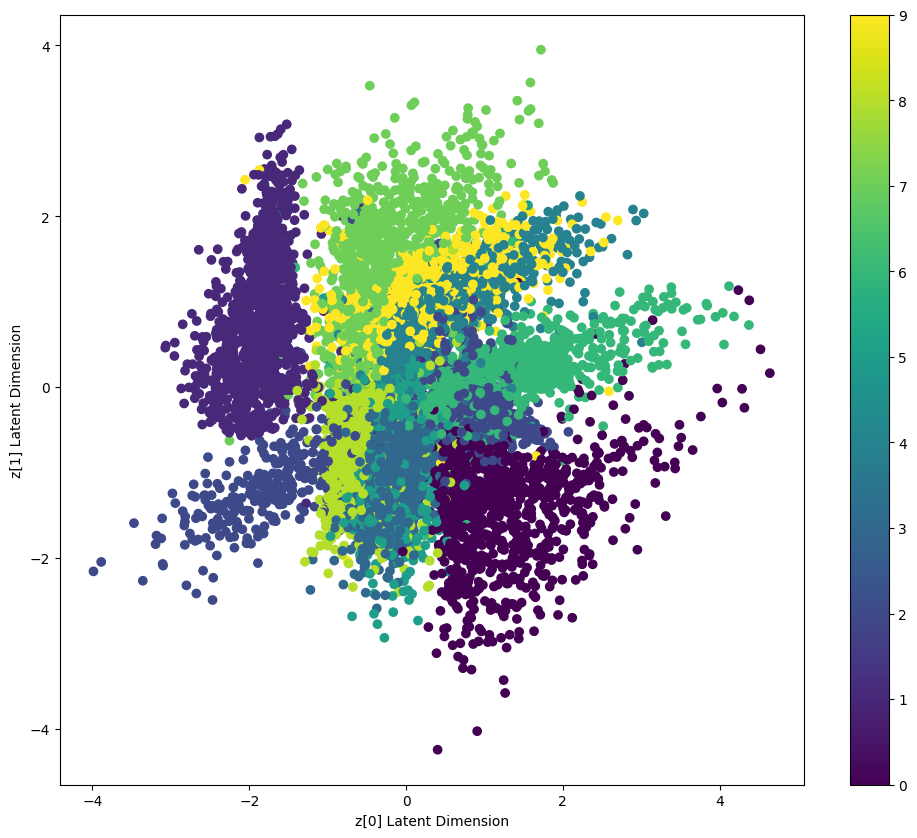

In [65]:
plot_digits(X_test, y, encoder)

<h3>With Fashion Mnist Dataset</h3>

In [15]:
(X_train,_), (X_test,y) = load_data('fashion_mnist', labels=True)

In [16]:
def plot(y_true):    
    f, ax = plt.subplots(1, 10, figsize=(15, 2))
    for i in range(10):
        ax[i].imshow(np.reshape(y_true[i], (28, 28)), aspect='auto')
    plt.tight_layout()

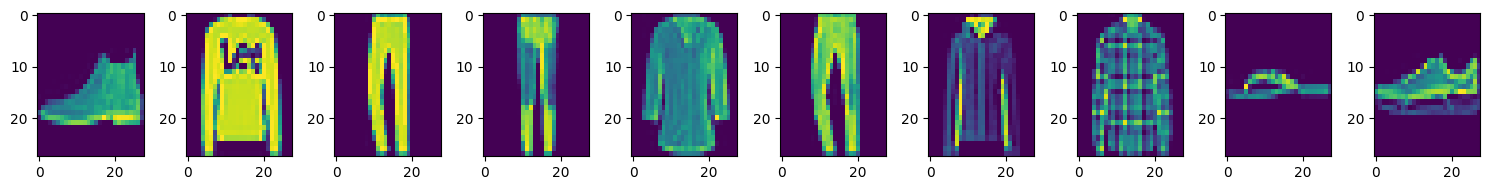

In [17]:
plot(X_test[:10])

In [18]:
vae.fit(X_train, epochs=epochs, batch_size=batch_size, validation_data=(X_test,None))

Epoch 1/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - loss: 42.0862 - val_loss: 34.0649
Epoch 2/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 33.3628 - val_loss: 32.6733
Epoch 3/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 32.1243 - val_loss: 31.6354
Epoch 4/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 31.4893 - val_loss: 31.1621
Epoch 5/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 31.0377 - val_loss: 30.6547
Epoch 6/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 30.6479 - val_loss: 30.4005
Epoch 7/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 30.3738 - val_loss: 30.3936
Epoch 8/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 30.1151 - val_loss: 29.8549
Epoch 9/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 29.8535 - val_loss: 29.5668
Epoch 10/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 29.6011 - val_loss: 29.4212
Epoch 11/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 29.4103 - val_loss: 29.2371
Epoch 12/50
469/469 ━━━━━

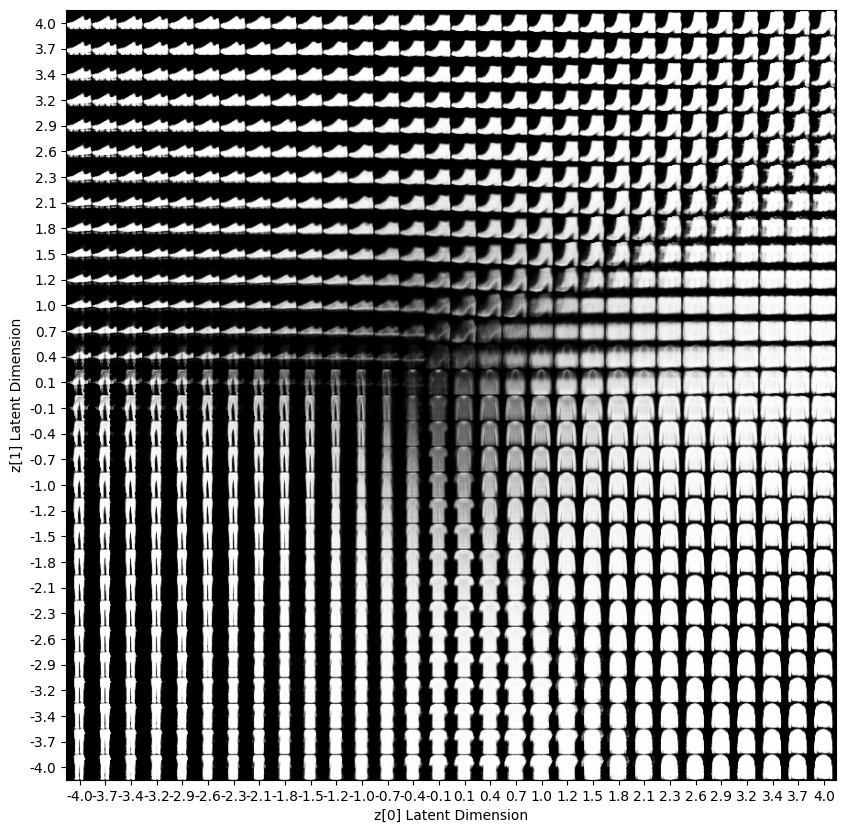

In [19]:
generate_manifold(decoder)

In [ ]:
.